# Feature Scaling

- In NN we need to scale the features to a similar range to ensure that the model converges faster and performs better.

- If we have features with different scales (e.g. Age and salary), the model takes more time to update the weights

- Read through the notebook, there are notes in between the code cells. You can also run the code cells to see the results.

In [35]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [10]:
import os
print(os.getcwd())         # shows runtime's working dir
print(os.listdir('.'))     # shows what files are actually there

/content
['.config', 'sample_data']


In [15]:
df = pd.read_csv('https://raw.githubusercontent.com/shivang98/Social-Network-ads-Boost/master/Social_Network_Ads.csv')

In [16]:
df = df.iloc[:,2:]
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [17]:
import seaborn as sns

<Axes: xlabel='Age', ylabel='EstimatedSalary'>

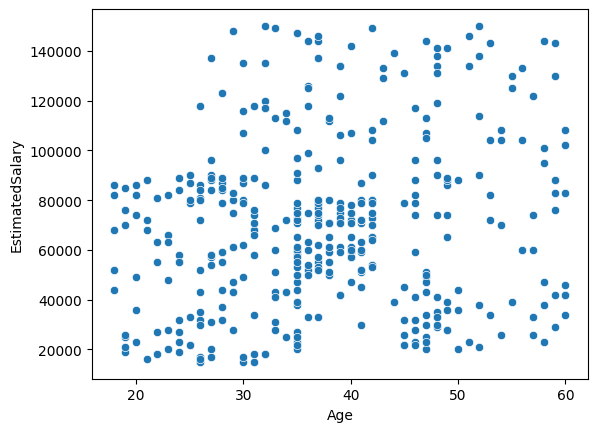

In [19]:
sns.scatterplot(x=df.iloc[:,0], y=df.iloc[:,1])

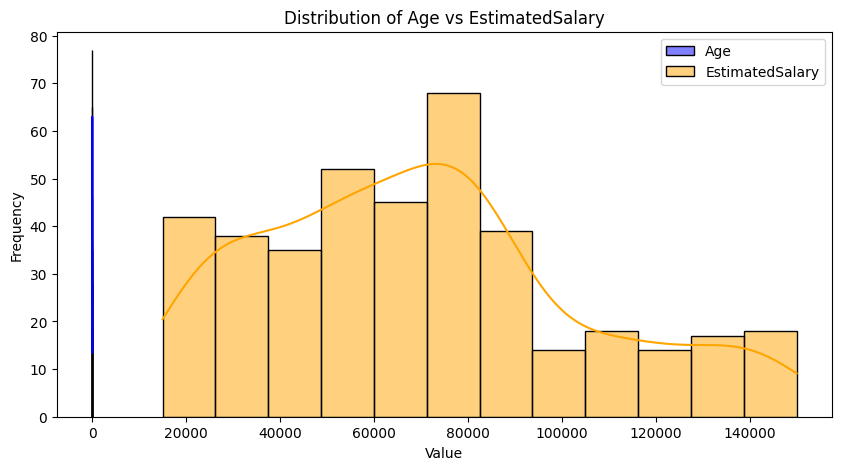

In [41]:
import seaborn as sns

plt.figure(figsize=(10,5))
sns.histplot(df['Age'], kde=True, color='blue', label='Age')
sns.histplot(df['EstimatedSalary'], kde=True, color='orange', label='EstimatedSalary')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Distribution of Age vs EstimatedSalary')
plt.legend()
plt.show()

In [20]:
X = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [21]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [22]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [23]:
model = Sequential()

model.add(Dense(128,activation='relu',input_dim=2))
model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [24]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [26]:
history = model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=100)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accuracy: 0.3969 - loss: 1696.1569 - val_accuracy: 0.6000 - val_loss: 888.3201
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6531 - loss: 825.5038 - val_accuracy: 0.6000 - val_loss: 279.9796
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3844 - loss: 422.0562 - val_accuracy: 0.4000 - val_loss: 31.6313
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6531 - loss: 260.8818 - val_accuracy: 0.6000 - val_loss: 40.1593
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4406 - loss: 174.1214 - val_accuracy: 0.6000 - val_loss: 201.1500
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5406 - loss: 101.2324 - val_accuracy: 0.6000 - val_loss: 141.2993
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5344 - loss: 113.3060 - val_accuracy: 0.6000 - val_loss: 64.2051
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5469 - loss: 57.5

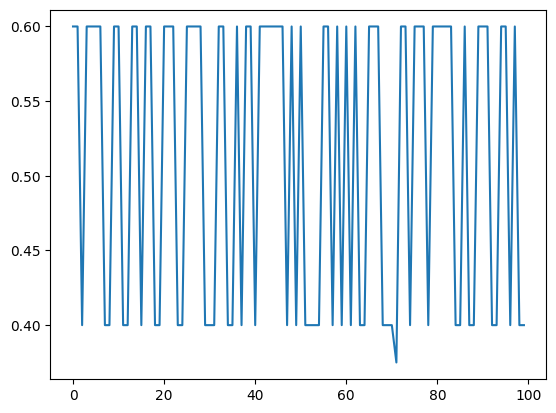

In [27]:
import matplotlib.pyplot as plt
plt.plot(history.history['val_accuracy'])

- See you can see the validation accuracy oscillated between 40% and 60% in the above graph. This is because the model is struggling to find the optimal weights due to the different scales of the features and never converges to an optimal weights.

# What is the reason behind this inconsistency in training?

- The reason is that while updating weight, for the feature with a larger scale (e.g. salary) will get more importance by the model and almost ignore the feature with a smaller scale (e.g. age). Leading to unstabilized training and never converging to an optimal weights.

## Geometric intuition

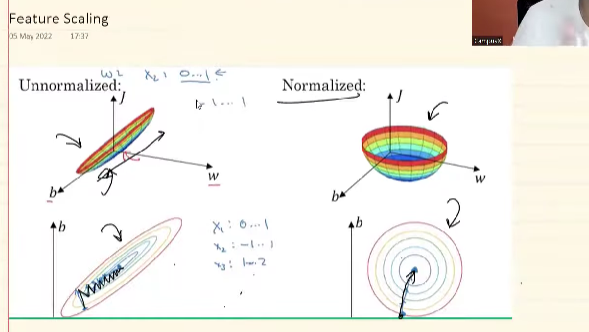

- The 3D plot of **unscaled features to the loss function** is a very elongated ellipsoid and unsymmetric. The gradient descent will take a long time to converge to the optimal weights because it will oscillate back and forth along the elongated direction of the ellipsoid.

- While the 3D plot of scaled features more of symmetric paraboloid. The gradient descent will converge much faster to the optimal weights because it will take a more direct path towards the minimum.

# Two ways to scale the features are:
1. Standardization (Z-score normalization){ Data range comes between -3 and 3 }
2. Min-Max Scaling (Normalization) { Data range comes between 0 and 1 }

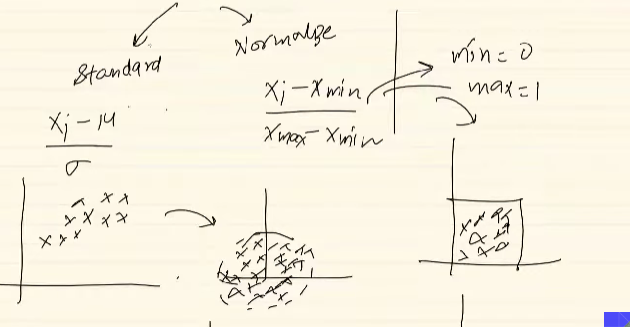

# When to use which one?

- If you know the min and max values of the features, then use Min-Max Scaling.
- Otherwise, use Standardization.

In [ ]:
# Applying scaling

In [28]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

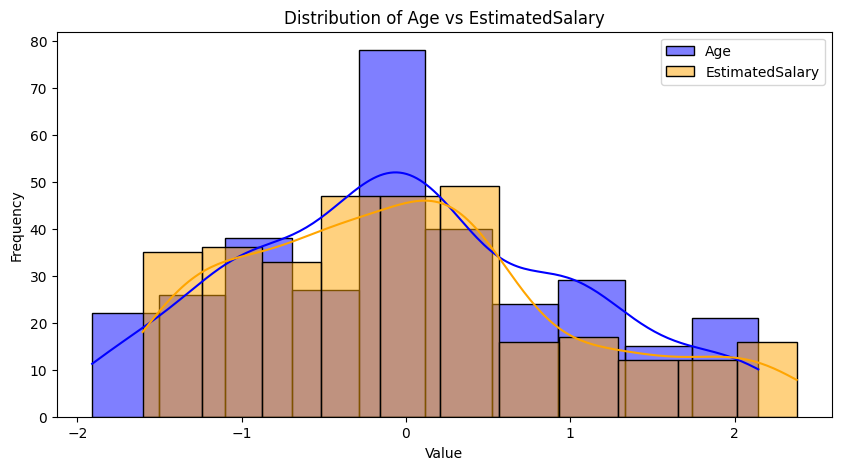

In [42]:
import seaborn as sns

plt.figure(figsize=(10,5))
sns.histplot(X_train_scaled[:, 0], kde=True, color='blue', label='Age')
sns.histplot(X_train_scaled[:, 1], kde=True, color='orange', label='EstimatedSalary')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Distribution of Age vs EstimatedSalary')
plt.legend()
plt.show()

In [29]:
X_train_scaled

array([[ 0.88928823, -0.65924556],
       [-0.17254846,  0.87392651],
       [-1.04132394, -0.36440478],
       [ 0.98581884,  0.6085698 ],
       [-0.94479333,  0.57908572],
       [ 0.40663519,  0.01888824],
       [ 0.98581884,  2.11225779],
       [ 0.31010458, -0.30543662],
       [ 1.7580637 , -0.27595254],
       [-0.17254846,  2.20071003],
       [ 1.7580637 ,  1.0213469 ],
       [-1.33091576, -1.48479975],
       [ 2.04765553,  0.54960165],
       [ 1.27541066,  1.90586924],
       [-1.13785454,  0.31372902],
       [-0.36560968, -0.77718187],
       [-1.71703819,  0.49063349],
       [-0.5586709 , -1.51428383],
       [ 0.31010458, -0.71821372],
       [ 0.02051275, -0.57079333],
       [ 0.02051275,  0.04837232],
       [-0.07601785, -0.51182517],
       [-0.6552015 , -1.51428383],
       [ 0.02051275,  0.31372902],
       [ 0.31010458,  0.07785639],
       [-0.46214029, -1.13099081],
       [-0.75173211, -1.54376791],
       [-0.26907907, -0.65924556],
       [-1.13785454,

<Axes: >

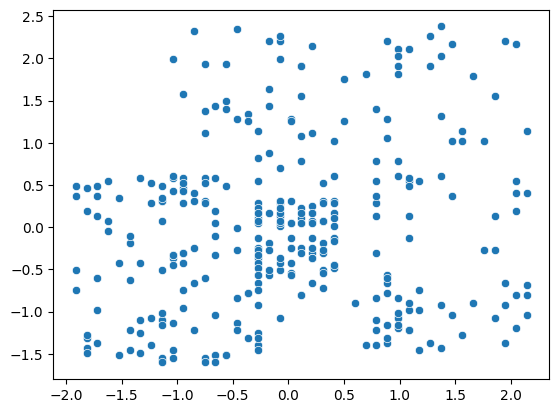

In [32]:
sns.scatterplot(x=X_train_scaled[:,0], y=X_train_scaled[:,1])

In [33]:
model = Sequential()

model.add(Dense(128,activation='relu',input_dim=2))
model.add(Dense(1,activation='sigmoid'))

model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

history = model.fit(X_train_scaled,y_train,validation_data=(X_test_scaled,y_test),epochs=100)

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.7469 - loss: 0.6180 - val_accuracy: 0.7625 - val_loss: 0.5803
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8094 - loss: 0.5694 - val_accuracy: 0.7750 - val_loss: 0.5324
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8406 - loss: 0.5296 - val_accuracy: 0.7875 - val_loss: 0.4926
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8438 - loss: 0.4937 - val_accuracy: 0.7875 - val_loss: 0.4592
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8438 - loss: 0.4642 - val_accuracy: 0.7875 - val_loss: 0.4312
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8500 - loss: 0.4376 - val_accuracy: 0.8000 - val_loss: 0.4065
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8562 - loss: 0.4137 - val_accuracy: 0.8125 - val_loss: 0.3855
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8750 - loss: 0.3935 - val_accuracy: 0.8375 - val_loss: 0

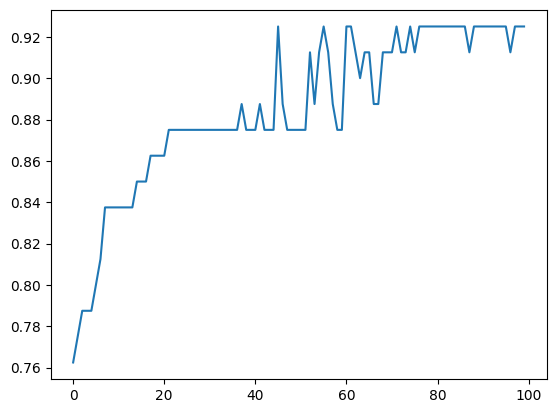

In [34]:
import matplotlib.pyplot as plt
plt.plot(history.history['val_accuracy'])

- See the validation accuracy is much more stable and converges to an optimal weights after scaling the features.